In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

print("Shape:", df.shape)
print(df.head())
print(df.isnull().sum())


Shape: (5000, 9)
      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  
lead_source    

In [3]:

categorical_columns = df.select_dtypes(
    include=[ "str"]
).columns

numerical_columns = df.select_dtypes(
    include=["number"]
).columns

df[categorical_columns] = df[categorical_columns].fillna("NA")
df[numerical_columns] = df[numerical_columns].fillna(0.0)

print("Missing values remaining:", df.isnull().sum().sum())


Missing values remaining: 0


In [4]:

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

print("Full dataset:", df.shape)
print("Full training set:", df_full_train.shape)
print("Training set:", df_train.shape)
print("Validation set:", df_val.shape)
print("Test set:", df_test.shape)


Full dataset: (5000, 9)
Full training set: (4000, 9)
Training set: (3000, 9)
Validation set: (1000, 9)
Test set: (1000, 9)


In [5]:

y_train = df_train["converted"].values

numerical_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

for feature in numerical_features:
    auc = roc_auc_score(y_train, df_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    print(feature, round(auc, 3))


lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


In [9]:


df_train_q2 = df_train.drop(columns=["converted"]).copy()
df_val_q2 = df_val.drop(columns=["converted"]).copy()

y_train = df_train["converted"].values
y_val = df_val["converted"].values


train_dicts = df_train_q2.to_dict(orient="records")
val_dicts = df_val_q2.to_dict(orient="records")


dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)



Training features: (3000, 28)
Validation features: (1000, 28)


In [11]:


for X in [X_train, X_val]:
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)

print("Training indices:", X_train.indices.dtype)
print("Validation indices:", X_val.indices.dtype)


Training indices: int32
Validation indices: int32


In [12]:

model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

y_val_proba = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_val_proba)

print("Validation ROC AUC:", round(auc, 3))


Validation ROC AUC: 0.732


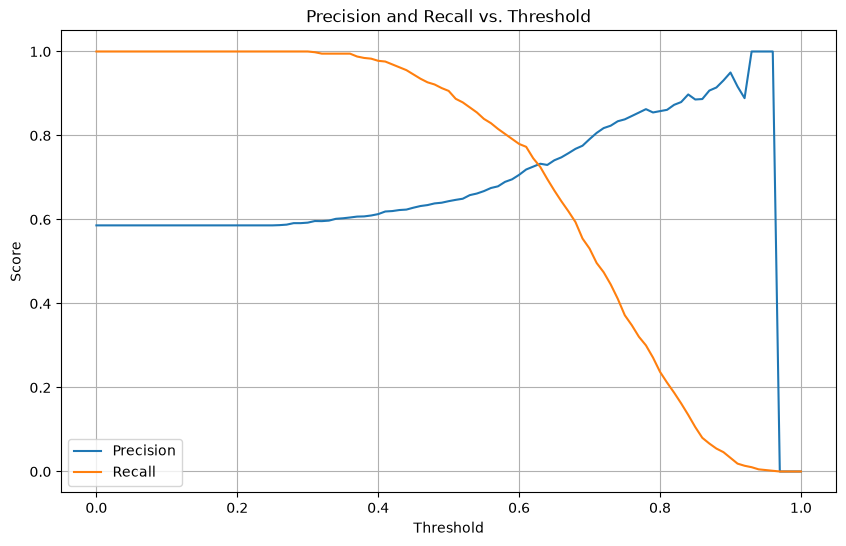

In [13]:

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for threshold in thresholds:
    y_pred = (y_val_proba >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    precisions.append(precision)
    recalls.append(recall)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Threshold")
plt.legend()
plt.grid(True)
plt.show()


In [14]:

valid_indices = [
    i for i, (p, r) in enumerate(zip(precisions, recalls))
    if not (p == 0 and r == 0)
]

best_index = min(
    valid_indices,
    key=lambda i: abs(precisions[i] - recalls[i])
)

print("Threshold:", round(thresholds[best_index], 2))
print("Precision:", round(precisions[best_index], 3))
print("Recall:", round(recalls[best_index], 3))
print(
    "Absolute difference:",
    round(abs(precisions[best_index] - recalls[best_index]), 3)
)


Threshold: 0.63
Precision: 0.733
Recall: 0.725
Absolute difference: 0.008


In [15]:

f1_scores = []

for threshold in thresholds:
    y_pred = (y_val_proba >= threshold).astype(int)

    score = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1_scores.append(score)

best_index = np.argmax(f1_scores)

print("Best threshold:", round(thresholds[best_index], 2))
print("Maximum F1 score:", round(f1_scores[best_index], 3))


Best threshold: 0.41
Maximum F1 score: 0.758


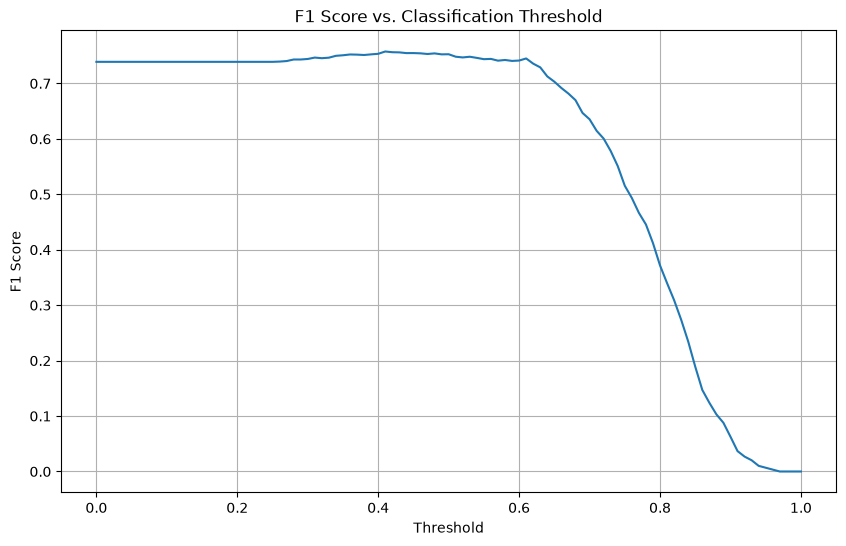

In [16]:

plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores)
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs. Classification Threshold")
plt.grid(True)
plt.show()


In [17]:

from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_fold_train = df_full_train.iloc[train_idx].copy()
    df_fold_val = df_full_train.iloc[val_idx].copy()

    y_fold_train = df_fold_train["converted"].values
    y_fold_val = df_fold_val["converted"].values

    X_fold_train_df = df_fold_train.drop(columns=["converted"])
    X_fold_val_df = df_fold_val.drop(columns=["converted"])

    train_dicts = X_fold_train_df.to_dict(orient="records")
    val_dicts = X_fold_val_df.to_dict(orient="records")

    dv_fold = DictVectorizer(sparse=True)
    X_fold_train = dv_fold.fit_transform(train_dicts)
    X_fold_val = dv_fold.transform(val_dicts)

  
    for X in [X_fold_train, X_fold_val]:
        X.indices = X.indices.astype(np.int32)
        X.indptr = X.indptr.astype(np.int32)

    model_fold = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(X_fold_train, y_fold_train)

    y_fold_proba = model_fold.predict_proba(X_fold_val)[:, 1]
    score = roc_auc_score(y_fold_val, y_fold_proba)

    scores.append(score)
    print(f"Fold {len(scores)} AUC: {score:.3f}")

print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3))


Fold 1 AUC: 0.731
Fold 2 AUC: 0.730
Fold 3 AUC: 0.736
Fold 4 AUC: 0.741
Fold 5 AUC: 0.721
Mean AUC: 0.732
Standard deviation: 0.007


In [18]:

C_values = [0.000001, 0.001, 1]

for C in C_values:
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx].copy()
        df_fold_val = df_full_train.iloc[val_idx].copy()

        y_fold_train = df_fold_train["converted"].values
        y_fold_val = df_fold_val["converted"].values

        X_fold_train_df = df_fold_train.drop(columns=["converted"])
        X_fold_val_df = df_fold_val.drop(columns=["converted"])

        train_dicts = X_fold_train_df.to_dict(orient="records")
        val_dicts = X_fold_val_df.to_dict(orient="records")

        dv_fold = DictVectorizer(sparse=True)

        X_fold_train = dv_fold.fit_transform(train_dicts)
        X_fold_val = dv_fold.transform(val_dicts)

        # Work around the sparse-matrix index issue
        for X in [X_fold_train, X_fold_val]:
            X.indices = X.indices.astype(np.int32)
            X.indptr = X.indptr.astype(np.int32)

        model_fold = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model_fold.fit(X_fold_train, y_fold_train)

        y_fold_proba = model_fold.predict_proba(X_fold_val)[:, 1]
        score = roc_auc_score(y_fold_val, y_fold_proba)

        scores.append(score)

    print(
        f"C={C}: mean={np.mean(scores):.3f}, "
        f"std={np.std(scores):.3f}"
    )


C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007
